In [1]:
from pathlib import Path
from urllib.parse import urlsplit

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tldextract

pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 160)
plt.rcParams["font.family"] = "Malgun Gothic"   # 한글 폰트 (Windows)
plt.rcParams["axes.unicode_minus"] = False
sns.set_theme(style="whitegrid", font="Malgun Gothic")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw" / "PhiUSIIL_Phishing_URL_Dataset.csv"
PROC = ROOT / "data" / "processed"
FIG = ROOT / "reports" / "figures"
PROC.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = {0: "정상", 1: "피싱"}   # is_phishing 기준

In [2]:
df = pd.read_csv(RAW, encoding="utf-8-sig")
df["is_phishing"] = 1 - df["label"]
print(df.shape)
df.head(3)

(235795, 57)


,FILENAME,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,URLCharProb,TLDLength,NoOfSubDomain,HasObfuscation,NoOfObfuscatedChar,ObfuscationRatio,NoOfLettersInURL,LetterRatioInURL,NoOfDegitsInURL,DegitRatioInURL,NoOfEqualsInURL,NoOfQMarkInURL,NoOfAmpersandInURL,NoOfOtherSpecialCharsInURL,SpacialCharRatioInURL,IsHTTPS,LineOfCode,LargestLineLength,HasTitle,Title,DomainTitleMatchScore,URLTitleMatchScore,HasFavicon,Robots,IsResponsive,NoOfURLRedirect,NoOfSelfRedirect,HasDescription,NoOfPopup,NoOfiFrame,HasExternalFormSubmit,HasSocialNet,HasSubmitButton,HasHiddenFields,HasPasswordField,Bank,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label,is_phishing
0,521848.txt,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,0.061933,3,1,0,0,0.0,18,0.581,0,0.0,0,0,0,1,0.032,1,558,9381,1,à¸‚à¹ˆà¸²à¸§à¸ªà¸” à¸‚à¹ˆà¸²à¸§à¸§à¸±à¸™à¸™à¸µ...,0.000000,0.000000,0,1,1,0,0,0,0,1,0,0,1,1,0,1,0,0,1,34,20,28,119,0,124,1,0
1,31372.txt,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,0.050207,2,1,0,0,0.0,9,0.391,0,0.0,0,0,0,2,0.087,1,618,9381,1,johannes gutenberg-universitÃ¤t mainz,55.555556,55.555556,1,1,0,0,0,0,0,0,0,1,1,0,0,0,0,0,1,50,9,8,39,0,217,1,0
2,597387.txt,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,0.064129,2,2,0,0,0.0,15,0.517,0,0.0,0,0,0,2,0.069,1,467,682,1,voice fm southampton,46.666667,46.666667,0,1,1,0,0,1,0,0,0,0,1,1,0,0,0,0,1,10,2,7,42,2,5,1,0


In [3]:
TEXT_COLS = ["FILENAME", "URL", "Domain", "TLD", "Title"]
num_cols = [c for c in df.columns if c not in TEXT_COLS + ["label", "is_phishing"]]
binary_cols = [c for c in num_cols if set(df[c].unique()) <= {0, 1}]
cont_cols = [c for c in num_cols if c not in binary_cols]
print(f"텍스트 {len(TEXT_COLS)}개, 수치 {len(cont_cols)}개, 이진 {len(binary_cols)}개 (라벨 제외)")
print("이진:", binary_cols)

텍스트 5개, 수치 31개, 이진 19개 (라벨 제외)
이진: ['IsDomainIP', 'HasObfuscation', 'IsHTTPS', 'HasTitle', 'HasFavicon', 'Robots', 'IsResponsive', 'NoOfURLRedirect', 'NoOfSelfRedirect', 'HasDescription', 'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton', 'HasHiddenFields', 'HasPasswordField', 'Bank', 'Pay', 'Crypto', 'HasCopyrightInfo']


In [4]:
desc = df[num_cols].describe().T
desc["n_unique"] = df[num_cols].nunique()
desc

,count,mean,std,min,25%,50%,75%,max,n_unique
URLLength,235795.0,34.573095,41.314153,13.000000,23.000000,27.000000,34.000000,6.097000e+03,482
DomainLength,235795.0,21.470396,9.150793,4.000000,16.000000,20.000000,24.000000,1.100000e+02,101
IsDomainIP,235795.0,0.002706,0.051946,0.000000,0.000000,0.000000,0.000000,1.000000e+00,2
URLSimilarityIndex,235795.0,78.430778,28.976055,0.155574,57.024793,100.000000,100.000000,1.000000e+02,36360
CharContinuationRate,235795.0,0.845508,0.216632,0.000000,0.680000,1.000000,1.000000,1.000000e+00,898
TLDLegitimateProb,235795.0,0.260423,0.251628,0.000000,0.005977,0.079963,0.522907,5.229071e-01,465
URLCharProb,235795.0,0.055747,0.010587,0.001083,0.050747,0.057970,0.062875,9.082366e-02,227421
TLDLength,235795.0,2.764456,0.599739,2.000000,2.000000,3.000000,3.000000,1.300000e+01,12
NoOfSubDomain,235795.0,1.164758,0.600969,0.000000,1.000000,1.000000,1.000000,1.000000e+01,10
HasObfuscation,235795.0,0.002057,0.045306,0.000000,0.000000,0.000000,0.000000,1.000000e+00,2


## 1. 결측치

In [5]:
na = df.isna().sum()
print("결측치가 있는 열:", na[na > 0].to_dict() or "없음")
# 빈 문자열도 확인
for c in TEXT_COLS:
    print(f"{c:10s} 빈 문자열: {(df[c].astype(str).str.strip() == '').sum()}")

결측치가 있는 열: 없음
FILENAME   빈 문자열: 0
URL        빈 문자열: 0


Domain     빈 문자열: 0
TLD        빈 문자열: 0
Title      빈 문자열: 0


## 2. 라벨 분포

In [6]:
vc = df["is_phishing"].value_counts().rename(CLASS_NAMES)
print(vc, "\n", (vc / len(df)).round(4))

is_phishing
정상    134850
피싱    100945
Name: count, dtype: int64 
 is_phishing
정상    0.5719
피싱    0.4281
Name: count, dtype: float64


## 3. 중복 URL과 라벨 충돌
- 같은 URL이 여러 번 나오는지
- 같은 URL이 정상/피싱 양쪽 라벨로 존재하는지 (충돌)
- 대소문자, 끝 슬래시만 다른 URL도 사실상 같은 주소로 볼 수 있어 정규화 버전도 확인한다.

In [7]:
def norm_url(u: str) -> str:
    u = u.strip().lower()
    return u[:-1] if u.endswith("/") else u

df["url_norm"] = df["URL"].map(norm_url)

for key in ["URL", "url_norm"]:
    g = df.groupby(key)["is_phishing"].agg(["size", "nunique"])
    dup = g[g["size"] > 1]
    conflict = g[g["nunique"] > 1]
    print(f"[{key}] 고유 {len(g):,} / 중복 그룹 {len(dup):,} (초과 행 {int((dup['size']-1).sum()):,})"
          f" / 라벨 충돌 그룹 {len(conflict):,} (행 {int(conflict['size'].sum()):,})")

[URL] 고유 235,370 / 중복 그룹 425 (초과 행 425) / 라벨 충돌 그룹 0 (행 0)


[url_norm] 고유 234,206 / 중복 그룹 1,581 (초과 행 1,589) / 라벨 충돌 그룹 1 (행 2)


In [8]:
conf_keys = df.groupby("url_norm")["is_phishing"].nunique().loc[lambda s: s > 1].index
df[df["url_norm"].isin(conf_keys)].sort_values("url_norm")[["URL", "is_phishing", "FILENAME"]].head(20)

,URL,is_phishing,FILENAME
36057,https://www.education.gouv.fr/,1,8116251.txt
84900,https://www.education.gouv.fr,0,19639.txt


In [9]:
# 같은 URL인데 피처 값이 다른 경우가 있는지 (중복 제거 시 어느 행을 남길지 판단용)
dup_rows = df[df.duplicated("URL", keep=False)]
n_diff = dup_rows.groupby("URL")[num_cols].nunique().gt(1).any(axis=1).sum()
print(f"중복 URL 중 수치 피처 값이 서로 다른 그룹: {n_diff}")

중복 URL 중 수치 피처 값이 서로 다른 그룹: 425


## 5. `FILENAME` 열 점검 (누수 위험)
`FILENAME`은 수집할 때 저장한 페이지 소스 파일 이름이다. 이름 규칙이 클래스별로 다르면 그 자체로 라벨을 알려준다.

In [10]:
df["fn_prefix"] = df["FILENAME"].str.extract(r"^([A-Za-z_]*)")[0].replace("", "(숫자만)")
pd.crosstab(df["fn_prefix"], df["is_phishing"].map(CLASS_NAMES), margins=True)

is_phishing,정상,피싱,All
fn_prefix,,,
(숫자만),134850,55211,190061
m,0,381,381
mw,0,36286,36286
op,0,589,589
oph,0,8478,8478
All,134850,100945,235795


In [11]:
fn_num = pd.to_numeric(df["FILENAME"].str.extract(r"(\d+)")[0], errors="coerce")
df.assign(fn_num=fn_num).groupby(df["is_phishing"].map(CLASS_NAMES))["fn_num"].describe()

,count,mean,std,min,25%,50%,75%,max
is_phishing,,,,,,,,
정상,134850.0,4.436583e+05,2.730942e+05,9.0,154342.25,484217.0,657440.5,904971.0
피싱,100945.0,4.425174e+06,3.963016e+06,1.0,66023.00,7960087.0,8065332.0,8139518.0


> `FILENAME`은 **어떤 시나리오에서도 입력에서 제외**한다. 접두어와 번호 범위가 클래스별로 다르면 라벨과 직결되는 식별자이기 때문이다.

## 6. 등록 가능 도메인(eTLD+1) 추출

In [12]:
print("tldextract", tldextract.__version__)
ext_pub = tldextract.TLDExtract(suffix_list_urls=(), include_psl_private_domains=False)
ext_priv = tldextract.TLDExtract(suffix_list_urls=(), include_psl_private_domains=True)

def etld1(extractor, url: str) -> str:
    r = extractor(url)
    if r.suffix and r.domain:
        return f"{r.domain}.{r.suffix}".lower()
    return (r.domain or urlsplit(url).hostname or url).lower()   # IP, localhost 등

df["etld1"] = [etld1(ext_priv, u) for u in df["URL"]]          # 소유자 단위 (기본)
df["etld1_public"] = [etld1(ext_pub, u) for u in df["URL"]]    # 플랫폼 단위
df["host"] = df["URL"].map(lambda u: (urlsplit(u).hostname or "").lower())

print("고유 Domain 열     :", df["Domain"].nunique())
print("고유 host           :", df["host"].nunique())
print("고유 eTLD+1 (private 포함):", df["etld1"].nunique())
print("고유 eTLD+1 (public만)    :", df["etld1_public"].nunique())
print("Domain 열과 host 불일치 행:", (df["Domain"].str.lower() != df["host"]).sum())

tldextract 5.4.0


고유 Domain 열     : 220086
고유 host           : 220077
고유 eTLD+1 (private 포함): 197709


고유 eTLD+1 (public만)    : 175509
Domain 열과 host 불일치 행: 36


In [13]:
# 두 기준이 갈리는 플랫폼(=public 기준에서 여러 private 도메인을 묶는 그룹)
plat = (df[df["etld1"] != df["etld1_public"]]
        .groupby("etld1_public")
        .agg(n_urls=("URL", "size"), n_owner_domains=("etld1", "nunique"), phishing_rate=("is_phishing", "mean"))
        .sort_values("n_urls", ascending=False))
print(f"영향받는 행: {plat['n_urls'].sum():,}")
plat.head(15)

영향받는 행: 26,451


,n_urls,n_owner_domains,phishing_rate
etld1_public,,,
web.app,5754,5527,1.000000
firebaseapp.com,5594,5418,1.000000
repl.co,3754,3348,1.000000
workers.dev,1438,784,1.000000
square.site,1199,1023,1.000000
dweb.link,959,767,1.000000
pantheonsite.io,900,735,1.000000
duckdns.org,643,558,0.998445
glitch.me,515,468,1.000000


### 6-1. 도메인별 URL 수 분포

In [14]:
def domain_table(key):
    return (df.groupby(key)
              .agg(n_urls=("URL", "size"), phishing_rate=("is_phishing", "mean"))
              .sort_values("n_urls", ascending=False))

for key in ["etld1", "etld1_public"]:
    t = domain_table(key)
    sizes = t["n_urls"]
    mixed = t[(t["phishing_rate"] > 0) & (t["phishing_rate"] < 1)]
    print(f"[{key}] 그룹 {len(t):,} | URL 1개짜리 비율 {(sizes == 1).mean():.3f} | "
          f"최대 {sizes.max():,} | 상위 10개 그룹이 차지하는 행 비율 {sizes.head(10).sum() / len(df):.3%} | "
          f"라벨 혼재 그룹 {len(mixed):,} (행 {mixed['n_urls'].sum():,})")

[etld1] 그룹 197,709 | URL 1개짜리 비율 0.961 | 최대 3,097 | 상위 10개 그룹이 차지하는 행 비율 4.055% | 라벨 혼재 그룹 106 (행 607)


[etld1_public] 그룹 175,509 | URL 1개짜리 비율 0.966 | 최대 5,754 | 상위 10개 그룹이 차지하는 행 비율 10.686% | 라벨 혼재 그룹 120 (행 1,374)


In [15]:
dom = domain_table("etld1")
dom.head(20)

,n_urls,phishing_rate
etld1,,
weeblysite.com,3097,1.000000
ipfs.io,1559,1.000000
xsph.ru,928,1.000000
google.com,782,1.000000
godaddysites.com,781,1.000000
webwave.dev,567,1.000000
weebly.com,555,1.000000
fleek.co,471,1.000000
tw1.ru,429,1.000000


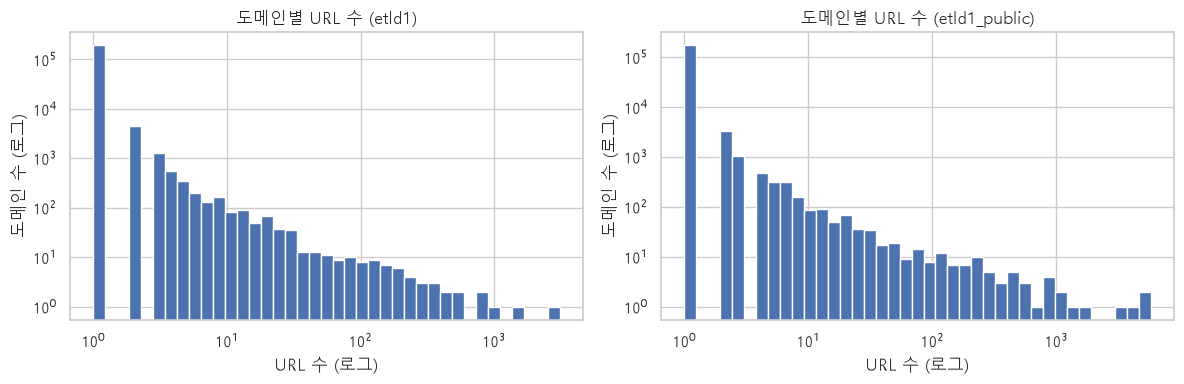

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, key in zip(axes, ["etld1", "etld1_public"]):
    s = domain_table(key)["n_urls"]
    ax.hist(s, bins=np.logspace(0, np.log10(s.max() + 1), 40), color="#4C72B0")
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_title(f"도메인별 URL 수 ({key})"); ax.set_xlabel("URL 수 (로그)"); ax.set_ylabel("도메인 수 (로그)")
plt.tight_layout(); plt.savefig(FIG / "01_domain_size_dist.png", dpi=150); plt.show()

In [17]:
# 라벨이 섞인 도메인 예시 (도메인 단위 분할에서 특히 중요)
mixed = dom[(dom["phishing_rate"] > 0) & (dom["phishing_rate"] < 1)]
mixed.head(15)

,n_urls,phishing_rate
etld1,,
pinata.cloud,276,0.996377
cutt.ly,36,0.972222
wikidot.com,19,0.947368
washington.edu,12,0.083333
clickfunnels.com,10,0.900000
adobe.com,9,0.888889
office.com,7,0.857143
odoo.com,7,0.857143
uni-heidelberg.de,7,0.285714


## 7. 수집 출처 편향 확인
정상 URL은 인기 사이트 순위 목록에서, 피싱 URL은 신고 목록에서 왔다면 정상은 짧은 메인 주소, 피싱은 긴 경로 주소가 많음
URL 문자열에서 직접 구조 정보를 다시 뽑아 클래스별로 비교

In [18]:
parts = df["URL"].map(urlsplit)
s = pd.DataFrame({
    "scheme": parts.map(lambda p: p.scheme.lower()),
    "has_www": df["host"].str.startswith("www."),
    "trailing_slash": df["URL"].str.endswith("/"),
    "path": parts.map(lambda p: p.path),
    "has_query": parts.map(lambda p: p.query != ""),
    "has_fragment": parts.map(lambda p: p.fragment != ""),
    "has_port": parts.map(lambda p: p.port is not None if p.hostname else False),
})
s["has_path"] = ~s["path"].isin(["", "/"])
s["is_main_page"] = ~s["has_path"] & ~s["has_query"] & ~s["has_fragment"]
s["path_depth"] = s["path"].str.strip("/").map(lambda x: 0 if x == "" else x.count("/") + 1)
s["url_len"] = df["URL"].str.len()
s["host_len"] = df["host"].str.len()
s["n_host_labels"] = df["host"].str.count(r"\.") + 1
s["is_phishing"] = df["is_phishing"]
for c in s.columns:
    if c not in ("path", "scheme", "is_phishing"):
        df[f"eda_{c}"] = s[c]

bias = s.groupby(s["is_phishing"].map(CLASS_NAMES))[
    ["has_www", "trailing_slash", "has_path", "has_query", "has_fragment", "has_port", "is_main_page"]
].mean().T.round(4)
bias

is_phishing,정상,피싱
has_www,1.0,0.4135
trailing_slash,0.0,0.3647
has_path,0.0,0.2720
has_query,0.0,0.0602
has_fragment,0.0,0.0082
has_port,0.0,0.0003
is_main_page,1.0,0.7160


In [19]:
pd.crosstab(s["scheme"], s["is_phishing"].map(CLASS_NAMES), normalize="columns").round(4)

is_phishing,정상,피싱
scheme,,
http,0.0,0.5126
https,1.0,0.4874


In [20]:
s.groupby(s["is_phishing"].map(CLASS_NAMES))[["url_len", "host_len", "path_depth", "n_host_labels"]].describe().T.round(2)

is_phishing                 정상         피싱
url_len       count  134850.00  100945.00
              mean       27.23      46.24
              std         4.82      61.07
              min        16.00      14.00
              25%        24.00      26.00
              50%        27.00      34.00
              75%        30.00      48.00
              max        58.00    6097.00
host_len      count  134850.00  100945.00
              mean       19.23      24.46
              std         4.82      12.20
              min         8.00       4.00
              25%        16.00      16.00
              50%        19.00      22.00
              75%        22.00      29.00
              max        50.00     110.00
path_depth    count  134850.00  100945.00
              mean        0.00       0.59
              std         0.00       1.27
              min         0.00       0.00
              25%         0.00       0.00
              50%         0.00       0.00
              75%         0.00       1.00
              max         0.00      33.00
n_host_labels count  134850.00  100945.00
              mean        3.16       3.17
              std         0.40       0.79
              min         3.00       2.00
              25%         3.00       3.00
              50%         3.00       3.00
              75%         3.00       3.00
              max         6.00      12.00

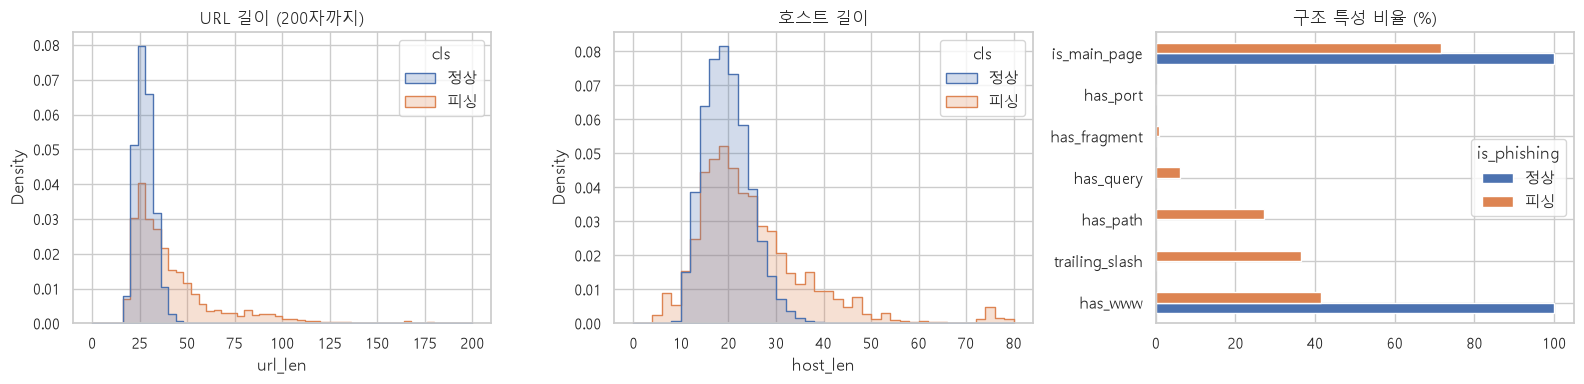

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
plot_df = s.assign(cls=s["is_phishing"].map(CLASS_NAMES))
sns.histplot(plot_df, x="url_len", hue="cls", bins=np.arange(0, 201, 4), stat="density",
             common_norm=False, element="step", ax=axes[0])
axes[0].set_title("URL 길이 (200자까지)")
sns.histplot(plot_df, x="host_len", hue="cls", bins=np.arange(0, 81, 2), stat="density",
             common_norm=False, element="step", ax=axes[1])
axes[1].set_title("호스트 길이")
(bias * 100).plot.barh(ax=axes[2]); axes[2].set_title("구조 특성 비율 (%)")
plt.tight_layout(); plt.savefig(FIG / "01_collection_bias.png", dpi=150); plt.show()

In [22]:
# '메인 주소'만 남겼을 때의 클래스 구성: 길이 분포를 맞춘 부분집합(S3 보조 평가) 후보
main = s[s["is_main_page"]]
print(f"메인 주소 행: {len(main):,} ({len(main)/len(s):.1%})")
print(main["is_phishing"].map(CLASS_NAMES).value_counts())

메인 주소 행: 207,122 (87.8%)
is_phishing
정상    134850
피싱     72272
Name: count, dtype: int64


### 7-1. 정상 URL의 형태가 하나로 고정되어 있는지
위 표에서 정상 URL은 `https` 100%, `www.` 100%, 경로·쿼리 0%로 나왔다. 정상 URL 전체가 `https://www.<호스트>` 한 가지 형태인지 정규식으로 확인

In [23]:
LEGIT_FORM = r"^https://www\.[^/?#]+$"
df["eda_legit_form"] = df["URL"].str.match(LEGIT_FORM)
print(pd.crosstab(df["eda_legit_form"], df["is_phishing"].map(CLASS_NAMES), margins=True))

# 규칙 하나: '이 형태면 정상, 아니면 피싱' 으로 맞히는 비율 (학습 없음, 편향 규모 확인용)
rule_acc = ((~df["eda_legit_form"]).astype(int) == df["is_phishing"]).mean()
print(f"\n형태 규칙 하나로 맞히는 비율: {rule_acc:.4f}")

is_phishing         정상      피싱     All
eda_legit_form                        
False                0  100318  100318
True            134850     627  135477
All             134850  100945  235795

형태 규칙 하나로 맞히는 비율: 0.9973


In [24]:
# 같은 형태 안에서만 비교하면 길이 차이가 남는가 (S3 보조 평가용 부분집합 후보)
df[df["eda_legit_form"]].groupby(df["is_phishing"].map(CLASS_NAMES))["URL"].apply(lambda u: u.str.len().describe()).unstack().round(2)

,count,mean,std,min,25%,50%,75%,max
is_phishing,,,,,,,,
정상,134850.0,27.23,4.82,16.0,24.0,27.0,30.0,58.0
피싱,627.0,31.80,8.93,17.0,25.0,30.0,37.5,101.0


### 7-2. 피싱 URL 형태 분류
피싱 URL을 scheme, `www.` 유무, 호스트 뒤 부분(없음 / 끝 슬래시만 / 경로 / 쿼리)으로 나눠 어떤 형태가 많은지 확인
정상 URL은 7-1에서 본 것처럼 `https` + `www.` + 없음 한 가지뿐

In [25]:
def url_form(u: str) -> tuple:
    p = urlsplit(u)
    if p.query:
        tail = "쿼리"
    elif p.path not in ("", "/"):
        tail = "경로"
    elif p.path == "/":
        tail = "끝 슬래시만"
    else:
        tail = "없음"
    return p.scheme.lower(), u.lower().split("://", 1)[-1].startswith("www."), tail

forms = pd.DataFrame(df["URL"].map(url_form).tolist(), columns=["scheme", "www", "tail"], index=df.index)
df["eda_form"] = forms["scheme"] + "|" + forms["www"].map({True: "www", False: "no-www"}) + "|" + forms["tail"]

phish = df["is_phishing"] == 1
form_tbl = (df[phish].groupby("eda_form")
              .agg(n=("URL", "size"), mean_len=("URL", lambda u: u.str.len().mean()))
              .sort_values("n", ascending=False))
form_tbl["pct"] = (form_tbl["n"] / phish.sum() * 100).round(2)
form_tbl["mean_len"] = form_tbl["mean_len"].round(1)
print("정상 URL 형태:", df.loc[~phish, "eda_form"].value_counts().to_dict())
print("정상 URL 평균 길이:", round(df.loc[~phish, "URL"].str.len().mean(), 1))
form_tbl

정상 URL 형태: {'https|www|없음': 134850}
정상 URL 평균 길이: 27.2


,n,mean_len,pct
eda_form,,,
http|www|없음,36392,27.2,36.05
https|no-www|끝 슬래시만,25994,39.4,25.75
https|no-www|경로,15462,65.1,15.32
http|no-www|경로,4538,55.6,4.50
http|no-www|끝 슬래시만,4310,35.2,4.27
https|no-www|쿼리,3666,134.7,3.63
http|no-www|없음,1870,28.4,1.85
http|no-www|쿼리,1734,161.4,1.72
https|no-www|없음,1625,41.0,1.61


In [26]:
# 상위 형태별 예시
for f in form_tbl.index[:6]:
    ex = df.loc[phish & (df["eda_form"] == f), "URL"].sample(4, random_state=1).tolist()
    print(f"[{f}]", *ex, sep="\n  ")

[http|www|없음]
  http://www.dronebazar.com
  http://www.vr.lt
  http://www.iqhost.us
  http://www.melodyv.cf
[https|no-www|끝 슬래시만]
  https://dev-www-itaumail24hs-com-py-paginas-atencion-para-vos.pantheonsite.io/
  https://mybusinessflash.square.site/
  https://meta-business-appeal-12895719.web.app/
  https://mycentierbank-certify.web.app/
[https|no-www|경로]
  https://centrostudicede.com/wp-content/22986463374/page_settings/login.php
  https://connection-orangebank-certicode.derlma.com/7395428/
  https://centicarolinas.org/wp-includes/agsh/it-tk/it.php
  https://gateway.ipfs.io/ipfs/bafybeifp5xd7rlkiagub3plyvtm4cl7gzctw65ndle7cdxbczbsldlhgy4
[http|no-www|경로]
  http://foxvtjueur.temp.swtest.ru/www.sfr.fr-login-return_url/index.html
  http://u1965047.plsk.regruhosting.ru/260/
  http://www-servismobilu-eu.usrfiles.com/html/0e472f_4d9b2a88f72eb4191a8eb158b004ca1f.html
  http://206.189.191.231/zbi/ameli-carte-vitale/index.php
[http|no-www|끝 슬래시만]
  http://unam.myfreesites.net/
  http://emeline

[https|no-www|쿼리]
  https://ebanking-ch3-ubs-a3ab0.web.app/login.html?session=4whnd21atruhfi6g8oprsejszy6inglarwnptvtlralldtt0qdqelqmlo0492q2jjth7qvkow62wxpt4611tkg0o6apnv5lml1u0026amp;auth=c7df4609-7819-4ab6-b43a-409f4f077478
  https://niftygatewaydocs.com/?gclid=eaiaiqobchmixrc3krw3_aivzej3ch3pbqajeaayasaaegkgsvd_bwe
  https://myilukana.shop/?_=/main.html%234ez5ntef3j4ik3+yclvdbboamoa63g==
  https://media.worldvaping.com/wp-content/plugins/superstorefinder-wp/ssf-wp-admin/pages/ssf_wp_uploads_path/csv/import/ch/login/r%c3%bcckerstattung/inter/cc.php?error#_


In [27]:
# 상위 형태별 대표 호스팅 플랫폼 (public eTLD+1 기준)
for f in form_tbl.index[:3]:
    top = df.loc[phish & (df["eda_form"] == f), "etld1_public"].value_counts(normalize=True).head(5).round(3)
    print(f"[{f}]", top.to_dict())

[http|www|없음] {'xsph.ru': 0.025, 'aliyuncs.com': 0.006, 'nowurl.fun': 0.005, 'blocktrail.com': 0.005, 'cannca.shop': 0.005}
[https|no-www|끝 슬래시만] {'web.app': 0.209, 'firebaseapp.com': 0.209, 'weeblysite.com': 0.109, 'repl.co': 0.088, 'workers.dev': 0.045}
[https|no-www|경로] {'ipfs.io': 0.085, 'wixsite.com': 0.029, 'fleek.co': 0.027, 'repl.co': 0.025, 'cloudflare-ipfs.com': 0.023}


In [28]:
# 경로·쿼리가 있는 피싱 URL의 내용 키워드 비율 (%)
has_tail = phish & forms["tail"].isin(["경로", "쿼리"])
kw = ["login", "signin", "account", "verify", "secure", "bank", "wp-", ".php", ".html", "ipfs"]
print(f"경로·쿼리 있는 피싱: {has_tail.sum():,}개")
pd.Series({k: df.loc[has_tail, "URL"].str.lower().str.contains(k, regex=False).mean() * 100 for k in kw}).round(1)

경로·쿼리 있는 피싱: 28,489개


login      10.0
signin      2.9
account     2.7
verify      0.6
secure      1.2
bank        1.6
wp-         5.0
.php       18.4
.html      19.4
ipfs       13.3
dtype: float64

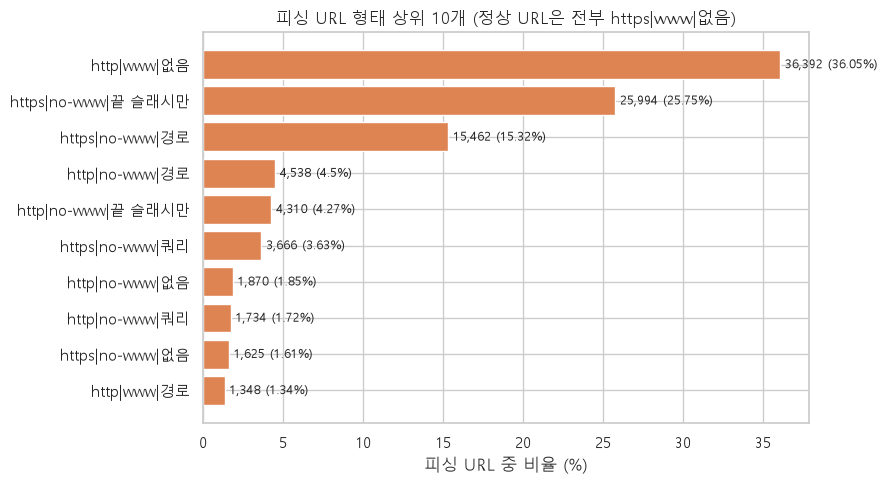

In [29]:
fig, ax = plt.subplots(figsize=(9, 5))
top_forms = form_tbl.head(10).iloc[::-1]
colors = ["#C44E52" if f == "https|www|없음" else "#DD8452" for f in top_forms.index]
ax.barh(top_forms.index, top_forms["pct"], color=colors)
for i, (n, pct) in enumerate(zip(top_forms["n"], top_forms["pct"])):
    ax.text(pct + 0.3, i, f"{n:,} ({pct}%)", va="center", fontsize=9)
ax.set_xlabel("피싱 URL 중 비율 (%)")
ax.set_title("피싱 URL 형태 상위 10개 (정상 URL은 전부 https|www|없음)")
plt.tight_layout(); plt.savefig(FIG / "01_phishing_url_forms.png", dpi=150); plt.show()

In [30]:
# 클래스별 무작위 URL 예시
for k, name in CLASS_NAMES.items():
    print(f"--- {name} ---")
    print("\n".join(df.loc[df["is_phishing"] == k, "URL"].sample(12, random_state=42).tolist()), "\n")

--- 정상 ---
https://www.atelierozmoz.be
https://www.diemon.com
https://www.wausauschools.org
https://www.paademode.com
https://www.boxturtles.com
https://www.mmstadium.com
https://www.brswimwear.com
https://www.leathercouncil.org
https://www.historync.org
https://www.toshin.com
https://www.autotech-co.com
https://www.everystudent.com 

--- 피싱 ---
http://www.soeme.com
http://www.v2cde1b0d66c767a23cfb34c14552836d3.ws
https://locateme.co.nz/wp-content/jam/ichiemagiksouthwest123.html
http://www.kwan078lj.web.app
https://jumptruegallery.000webhostapp.com/download-documents
https://www.jcb.dotcombinations.com/
https://www.1000bottlesparty.com/jp
http://www.artzvuk.by
https://leszek.arekhasnik.pl/add/email@example.com
https://193-42-33-145.cprapid.com/
http://www.procareinsurance.gr
https://inezkelley-1317634057.cos.na-siliconvalley.myqcloud.com/inezkelley.html 



## 8. 누수 후보 초안 (피처 정의 기준)
- 기준 A: 다른 URL이나 참조 집합과 비교해 계산된 값 
- 기준 B: 수집 과정, 페이지 구성 방식 때문에 라벨과 직접 연결될 수 있는 값
- 식별자: 수집 과정의 산물. 피처가 아니므로 무조건 제외한다.

In [31]:
leak_candidates = pd.DataFrame([
    ("FILENAME",            "식별자", "수집 파일명. 접두어/번호가 클래스별로 다름 (5절)"),
    ("URLSimilarityIndex",  "A", "참조(정상) URL 집합과의 유사도"),
    ("TLDLegitimateProb",   "A", "정상 URL 집합에서 계산한 TLD 출현 확률"),
    ("URLCharProb",         "A", "정상/피싱 URL 문자 빈도에서 계산한 확률"),
    ("CharContinuationRate","A?", "정의 확인 필요"),
    ("LineOfCode",          "B", "페이지 소스 줄 수: 수집 시점, 페이지 생존 여부에 좌우"),
    ("LargestLineLength",   "B", "페이지 소스 최장 줄 길이"),
    ("HasSocialNet",        "B", "정상 사이트 메인 페이지 구성 방식과 직결"),
    ("HasCopyrightInfo",    "B?", "정상 사이트 메인 페이지 구성 방식과 직결"),
    ("HasDescription",      "B?", "정상 사이트 메인 페이지 구성 방식과 직결"),
    ("NoOfExternalRef",     "B?", "페이지 크기에 비례"),
    ("NoOfSelfRef",         "B?", "페이지 크기에 비례"),
], columns=["feature", "criterion", "reason"])

cands = [f for f in leak_candidates["feature"] if f in num_cols]
summary = df.groupby(df["is_phishing"].map(CLASS_NAMES))[cands].agg(["median", "mean"]).T.unstack()
summary.columns = ["_".join(map(str, c)) for c in summary.columns]
leak_candidates.merge(summary.round(3), left_on="feature", right_index=True, how="left")

,feature,criterion,reason,정상_median,정상_mean,피싱_median,피싱_mean
0,FILENAME,식별자,수집 파일명. 접두어/번호가 클래스별로 다름 (5절),NaN,NaN,NaN,NaN
1,URLSimilarityIndex,A,참조(정상) URL 집합과의 유사도,100.000,100.000,51.419,49.617
2,TLDLegitimateProb,A,정상 URL 집합에서 계산한 TLD 출현 확률,0.523,0.282,0.018,0.232
3,URLCharProb,A,정상/피싱 URL 문자 빈도에서 계산한 확률,0.061,0.060,0.052,0.050
4,CharContinuationRate,A?,정의 확인 필요,1.000,0.933,0.727,0.728
5,LineOfCode,B,"페이지 소스 줄 수: 수집 시점, 페이지 생존 여부에 좌우",1105.000,1947.492,12.000,65.730
6,LargestLineLength,B,페이지 소스 최장 줄 길이,3066.000,7375.920,138.000,20021.448
7,HasSocialNet,B,정상 사이트 메인 페이지 구성 방식과 직결,1.000,0.795,0.000,0.005
8,HasCopyrightInfo,B?,정상 사이트 메인 페이지 구성 방식과 직결,1.000,0.808,0.000,0.057
9,HasDescription,B?,정상 사이트 메인 페이지 구성 방식과 직결,1.000,0.737,0.000,0.044


## 9. 정리된 데이터 저장

In [32]:
n0 = len(df)
df_clean = df.dropna(subset=["URL"]).copy()
conflict_urls = df_clean.groupby("URL")["is_phishing"].nunique().loc[lambda x: x > 1].index
df_clean = df_clean[~df_clean["URL"].isin(conflict_urls)]
n_conf = n0 - len(df_clean)
df_clean = df_clean.drop_duplicates("URL", keep="first")
n_dup = n0 - n_conf - len(df_clean)

print(f"원본 {n0:,} → 라벨 충돌 제거 {n_conf:,} → 중복 제거 {n_dup:,} → 최종 {len(df_clean):,}")
print(df_clean["is_phishing"].map(CLASS_NAMES).value_counts())

keep = (["URL", "Domain", "TLD", "Title", "etld1", "etld1_public"]
        + num_cols + ["label", "is_phishing"])
df_clean[keep].to_csv(PROC / "phiusiil_clean.csv", index=False, encoding="utf-8")
print("저장:", PROC / "phiusiil_clean.csv", df_clean[keep].shape)

원본 235,795 → 라벨 충돌 제거 0 → 중복 제거 425 → 최종 235,370
is_phishing
정상    134850
피싱    100520
Name: count, dtype: int64


저장: C:\Users\dong\Phishing Detection\data\processed\phiusiil_clean.csv (235370, 58)
